# Figure 2E (proposed replacement) — gRNA fitness effect vs sensor-measured editing

Kexin Dong

Last Updated: November 24, 2026

A proposed replacement for the Fig. 2E rank-ordered waterfall. Instead of
plotting LFC against an arbitrary rank, it plots each gRNA's LFC against the
**sensor measurement that licenses the call** — so the excluded (<20% editing)
zone, and whether a hit depends on editing depth, are visible in the same panel.

**ABE OG screen**, four contexts in one row.

### Why this rather than the waterfall

The waterfall's x-axis (rank) carries no measurement — it is a restatement of
the y-axis ordering. Putting sensor editing on x instead answers the question
the sensors exist to answer: *is this fitness effect accompanied by the edit it
is attributed to?* A hit sitting at 25% editing is a weaker claim than the same
LFC at 95%, and the waterfall cannot show that distinction.

### Conventions

- Point colour = COSMIC Cancer Gene Census role
- **Uniform point size.** Significance is shown only as significant vs not
  (FDR < 0.1 coloured, FDR ≥ 0.1 pale grey) — the earlier FDR-binned sizes
  made the dense panels unreadable.
- Labels = top/bottom *N* by LFC among significant, well-edited gRNAs
- Grey shading = gRNAs excluded by the editing cutoff

> **D5 is excluded**, matching `figure4a_UMAP_all_screens.ipynb`: it is the
> earliest in vitro timepoint, before selection has acted.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects as PathEffects
from matplotlib.patches import Patch
import seaborn as sns
from adjustText import adjust_text

warnings.filterwarnings('ignore')

# ── Global style: final print size, Nature look ───────────────────────────
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['text.usetex'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
mpl.rcParams.update({'mathtext.fontset': 'custom', 'mathtext.rm': 'Helvetica',
                     'mathtext.it': 'Arial:italic', 'mathtext.bf': 'Arial:bold'})
mpl.rcParams.update({'font.size': 7, 'axes.labelsize': 7, 'axes.titlesize': 7,
                     'xtick.labelsize': 6, 'ytick.labelsize': 6,
                     'legend.fontsize': 6, 'axes.linewidth': .6,
                     'lines.linewidth': .75, 'patch.linewidth': .5,
                     'xtick.major.width': .6, 'ytick.major.width': .6,
                     'xtick.major.size': 3, 'ytick.major.size': 3,
                     'legend.frameon': False, 'figure.dpi': 200})
MM = 1 / 25.4

greys = sns.color_palette('Greys').as_hex()

BASE = '/Users/kexindong/Documents/GitHub/B-ALL-in-vivo-base-editing/'
OUT_DIR = BASE + 'figures/fig2e-replacement/'
os.makedirs(OUT_DIR, exist_ok=True)
print('writing to', OUT_DIR)

writing to /Users/kexindong/Documents/GitHub/B-ALL-in-vivo-base-editing/figures/fig2e-replacement/


## Parameters

`MIN_EDIT` is the Fig. 2 cutoff. Unlike the UMAP notebook, the filter here is
**per tissue**: each panel shades and labels according to that tissue's own
sensor measurement, because the panel is about that context. Points below the
cutoff are still drawn (in the shaded zone) so the reader can see what the
threshold discards — they are simply never labelled.

In [2]:
# ── Filtering / display constants ────────────────────────────────────────
MIN_EDIT   = 20     # % target base editing — the Fig. 2 cutoff
FDR_CUTOFF = 0.1
MIN_INPUT  = 2      # median input counts
MIN_SENSOR_READS = 100
N_LABEL    = 5      # top / bottom N by LFC to label, per panel

# Contexts, in panel order. D5 omitted (see header).
TISSUES = ['d15', 'spleen', 'bm', 'men']
TISSUE_LABEL = {'d15': 'In Vitro', 'spleen': 'Spleen',
                'bm': 'Bone Marrow', 'men': 'Meninges'}

# COSMIC role colours — figure2_CLEANED convention
COSMIC_COLORS = {'Oncogene': 'tab:red', 'Oncogene/TSG': 'tab:purple',
                 'TSG': 'tab:blue', 'Undefined': 'tab:grey'}
ROLE_MAP = {'TSG': 'TSG', 'TSG, fusion': 'TSG', 'Undefined': 'Undefined',
            'fusion': 'Undefined', 'oncogene': 'Oncogene',
            'oncogene, TSG': 'Oncogene/TSG',
            'oncogene, TSG, fusion': 'Oncogene/TSG',
            'oncogene, fusion': 'Oncogene'}

# Uniform marker sizes: significance is colour, not area.
S_SIG = 14          # FDR < FDR_CUTOFF
S_NS  = 2.5         # FDR >= FDR_CUTOFF (pale grey background)

## Load and annotate

COSMIC roles are merged on the **human** gene symbol. Mouse symbols are title
case and *Trp53* ≠ *TP53*, so matching on the mouse symbol would silently drop
genes; `gene_name_h` is the correct key here.

In [3]:
def italic(g):
    return f'$\\it{{{g}}}$'


def load_abe():
    cos = pd.read_csv(
        BASE + 'source-data/Census_allSun Nov 17 02_26_47 2024.csv'
    ).fillna('Undefined')
    cos['role'] = cos['Role in Cancer'].map(ROLE_MAP).fillna('Undefined')
    cos = cos[['Gene Symbol', 'role']].drop_duplicates('Gene Symbol')

    d = pd.read_csv(BASE + 'LFC-FDR/ABE_OG_LFC_FDR.csv', low_memory=False)
    d = d.merge(cos, left_on='gene_name_h', right_on='Gene Symbol', how='left')
    d['role'] = d['role'].fillna('Undefined')
    d['color'] = d['role'].map(COSMIC_COLORS)
    print(f'ABE: {len(d)} rows, '
          f'{(d.classification == "targeting guide").sum()} targeting')
    print('roles:', dict(d.role.value_counts()))
    return d


def mutation_label(row):
    """'Gene A123B' with italic gene; fall back to the human change."""
    a = row['HGVSp_m']
    if pd.isna(a) or a in ('Not calculated (legacy)', 'Non-coding'):
        ah = row.get('HGVSp_h')
        a = f'{ah} (H)' if pd.notna(ah) else str(row['HGVSp_m'])
    return f"{italic(row['gene_name_m_corrected'])} {a}"


abe = load_abe()

ABE: 1070 rows, 1034 targeting
roles: {'TSG': np.int64(359), 'Oncogene': np.int64(328), 'Undefined': np.int64(197), 'Oncogene/TSG': np.int64(186)}


## Draw one panel

Labels are placed with `adjust_text` and then **clamped to the axes**: an
earlier version let it push text into neighbouring panels and over the titles.
Any label `adjust_text` moves outside the axes is pulled back inside, and its
leader line redrawn.

In [4]:
def panel(ax, d, tissue, show_ylabel):
    lfc_c  = f'LFC_median_{tissue}'
    fdr_c  = f'FDR_{tissue}_stouffers'
    edit_c = f'target_base_edit_perc_{tissue}'
    read_c = f'sensor_reads_{tissue}'

    t = d[(d['classification'] == 'targeting guide') &
          (d['Input_median'] >= MIN_INPUT) &
          (d[read_c] >= MIN_SENSOR_READS)].copy()
    t = t.dropna(subset=[lfc_c, edit_c, fdr_c])

    # excluded zone + zero line
    ax.axvspan(0, MIN_EDIT, color=greys[1], alpha=.45, lw=0, zorder=0)
    ax.axhline(0, color='black', ls='--', lw=.8, zorder=1)

    # not significant — pale grey background
    ns = t[t[fdr_c] >= FDR_CUTOFF]
    ax.scatter(ns[edit_c], ns[lfc_c], s=S_NS, color='lightgrey',
               linewidths=0, alpha=.5, zorder=2, rasterized=True)

    # significant — COSMIC colour, one uniform size
    sig = t[t[fdr_c] < FDR_CUTOFF]
    ax.scatter(sig[edit_c], sig[lfc_c], s=S_SIG, c=sig['color'],
               linewidth=.25, edgecolor='black', alpha=.85, zorder=3)

    # robust y-range so a few extreme guides don't compress the bulk
    lo = np.nanpercentile(t[lfc_c], .2)
    hi = np.nanpercentile(t[lfc_c], 99.8)
    pad = (hi - lo) * .10
    ax.set_ylim(lo - pad, hi + pad * 2.4)
    ax.set_xlim(-2, 102)

    # ── labels: top / bottom N among significant AND above the cutoff ─────
    passing = t[(t[fdr_c] < FDR_CUTOFF) &
                (t[edit_c] >= MIN_EDIT)].sort_values(lfc_c, ascending=False)
    tb = pd.concat([passing.head(N_LABEL), passing.tail(N_LABEL)])
    texts = [ax.text(r[edit_c], r[lfc_c], mutation_label(r), fontsize=5,
                     color=r['color'], zorder=5,
                     path_effects=[PathEffects.withStroke(
                         linewidth=1.4, foreground='white')])
             for _, r in tb.iterrows()]
    if texts:
        adjust_text(texts, ax=ax, expand=(1.5, 1.8),
                    force_text=(.5, .8), force_static=(.25, .4),
                    arrowprops=dict(arrowstyle='-', color='black', lw=.35,
                                    alpha=.8))
        # clamp anything adjust_text pushed outside this panel
        x0, x1 = ax.get_xlim()
        y0, y1 = ax.get_ylim()
        mx, my = (x1 - x0) * .02, (y1 - y0) * .02
        for tx in texts:
            px, py = tx.get_position()
            tx.set_position((min(max(px, x0 + mx), x1 - mx),
                             min(max(py, y0 + my), y1 - my)))

    ax.set_xticks([0, 20, 40, 60, 80, 100])
    ax.set_xticklabels(['0', '20', '40', '60', '80', '100%'])
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='both', which='major', labelsize=6, direction='out',
                   length=3, width=.6)
    if show_ylabel:
        ax.set_ylabel('gRNA LFC (median vs input)')

    n_pass = int((t[edit_c] >= MIN_EDIT).sum())
    n_hit = int(((t[fdr_c] < FDR_CUTOFF) & (t[edit_c] >= MIN_EDIT)).sum())
    ax.set_title(f'{TISSUE_LABEL[tissue]}  (n = {n_pass:,})', fontsize=6.5)
    return {'tissue': TISSUE_LABEL[tissue], 'n_plotted': len(t),
            'n_above_cutoff': n_pass, 'n_hits': n_hit}

## Assemble the figure

One row of four contexts. Each panel keeps its own y-limits: tissue LFC
spreads differ, and shared limits would flatten the meninges panel.


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


wrote /Users/kexindong/Documents/GitHub/B-ALL-in-vivo-base-editing/figures/fig2e-replacement/fig2e_ABE.pdf


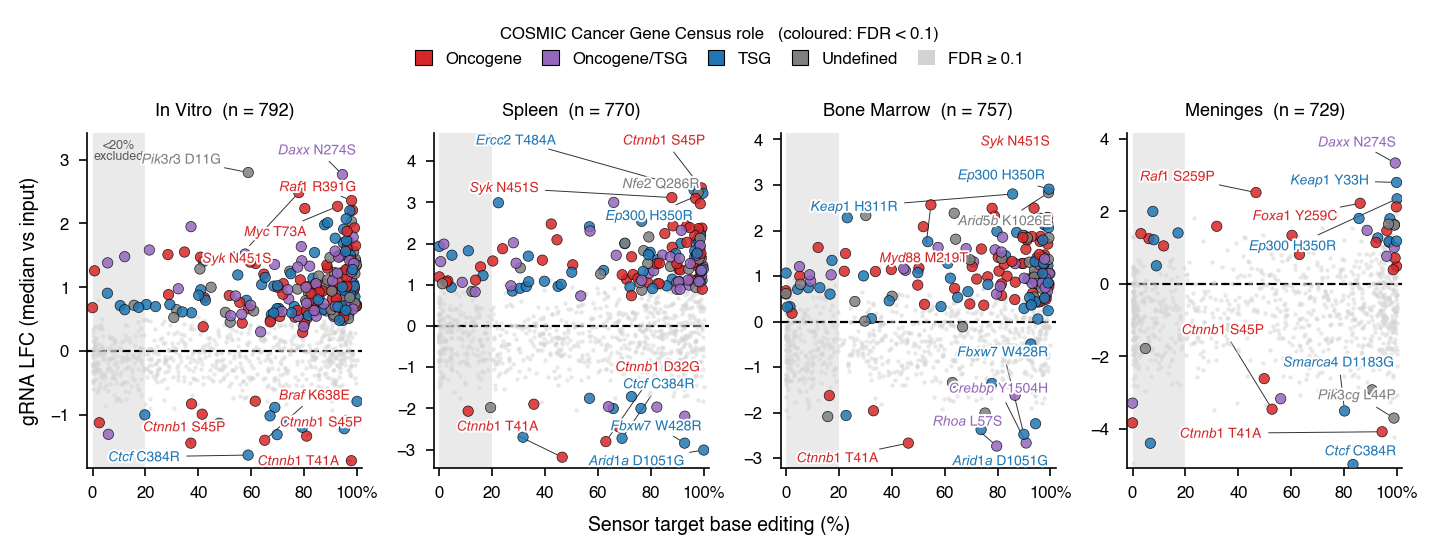

In [5]:
stats = []
fig, axs = plt.subplots(1, len(TISSUES), figsize=(183 * MM, 56 * MM))

for c_i, tis in enumerate(TISSUES):
    stats.append(panel(axs[c_i], abe, tis, show_ylabel=(c_i == 0)))

fig.text(.5, -.02, 'Sensor target base editing (%)', ha='center', fontsize=7)

# one legend: COSMIC role + the not-significant class
role_handles = [Patch(facecolor=COSMIC_COLORS[k], edgecolor='black', lw=.4,
                      label=k)
                for k in ['Oncogene', 'Oncogene/TSG', 'TSG', 'Undefined']]
role_handles.append(Patch(facecolor='lightgrey', edgecolor='none',
                          label=f'FDR \u2265 {FDR_CUTOFF}'))
leg = fig.legend(handles=role_handles, loc='lower center',
                 bbox_to_anchor=(.5, 1.0), ncol=5, fontsize=6,
                 frameon=False, handlelength=1, handleheight=1,
                 columnspacing=1.2,
                 title=f'COSMIC Cancer Gene Census role   '
                       f'(coloured: FDR < {FDR_CUTOFF})')
leg.get_title().set_fontsize(6)

axs[0].text(MIN_EDIT / 2, axs[0].get_ylim()[1] * .97,
            f'<{MIN_EDIT}%\nexcluded', fontsize=4.5, ha='center',
            va='top', color=greys[4], linespacing=.95)

fig.tight_layout()
fig.subplots_adjust(wspace=.26)

fig.savefig(OUT_DIR + 'fig2e_ABE.pdf', bbox_inches='tight')
fig.savefig(OUT_DIR + 'fig2e_ABE.png', dpi=200, bbox_inches='tight')
print('wrote', OUT_DIR + 'fig2e_ABE.pdf')
plt.show()

## Per-panel standalone PDFs

Single-column versions of each panel, for mixing into other figures.

In [6]:
for tis in TISSUES:
    f2, a2 = plt.subplots(figsize=(89 * MM, 66 * MM))
    panel(a2, abe, tis, show_ylabel=True)
    a2.set_xlabel('Sensor target base editing (%)')
    f2.tight_layout()
    f2.savefig(f'{OUT_DIR}fig2e_ABE_{tis}.pdf', bbox_inches='tight')
    plt.close(f2)
print('wrote', len(TISSUES), 'standalone ABE panels')

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


1 extra bytes in post.stringData array


... (11 outputs left out)

Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


wrote 4 standalone ABE panels


## Summary

`n_above_cutoff` is the number of gRNAs clearing the editing threshold in that
context — the set the panel's conclusions rest on. It varies by context, which
is exactly the point the sensors let us make.

In [7]:
summary = pd.DataFrame(stats)
summary.to_csv(OUT_DIR + 'fig2e_ABE_panel_summary.csv', index=False)
print(summary.to_string(index=False))
print()
print('files in', OUT_DIR)
for f in sorted(os.listdir(OUT_DIR)):
    print('  ', f)

     tissue  n_plotted  n_above_cutoff  n_hits
   In Vitro       1011             792     241
     Spleen       1016             770     143
Bone Marrow       1021             757     159
   Meninges       1013             729      35

files in /Users/kexindong/Documents/GitHub/B-ALL-in-vivo-base-editing/figures/fig2e-replacement/
   fig2e_ABE.pdf
   fig2e_ABE.png
   fig2e_ABE_bm.pdf
   fig2e_ABE_d15.pdf
   fig2e_ABE_men.pdf
   fig2e_ABE_panel_summary.csv
   fig2e_ABE_spleen.pdf
